In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 50)

df = pd.read_csv("indian_banking_transactions.csv")
print(df.shape)
df.head()

(550000, 20)


,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
0,TXN000000001,CUST015796,2019-01-01,15:28,Current,UPI,"1,820.17",Debit,"609,365.31",Food & Dining,Maharashtra,764,0,NaN,0.00,Success,Branch,Verified,0,15
1,TXN000000002,CUST000861,2019-01-01,03:00,Current,UPI,392.67,Credit,"14,451.14",Education,West Bengal,630,0,NaN,0.00,Success,Mobile_App,Verified,0,3
2,TXN000000003,CUST076821,2019-01-01,18:03,Fixed Deposit,POS,"1,255.97",Debit,"47,621.87",Utilities,Punjab,813,1,Home,"1,433.91",Success,Mobile_App,Verified,0,18
3,TXN000000004,CUST054887,2019-01-01,08:03,Savings,UPI,"2,580.68",Debit,"34,467.85",Travel,Karnataka,628,1,Personal,"6,280.35",Success,API,Verified,0,8
4,TXN000000005,CUST006266,2019-01-01,14:23,Fixed Deposit,UPI,"2,573.80",Debit,"26,617.40",Utilities,West Bengal,767,0,NaN,0.00,Success,API,Verified,0,14


In [2]:
# 1. Missing values (only show columns that have any)
nulls = df.isna().sum()
print(nulls[nulls > 0])

# 2. Duplicate transactions
print("Duplicate IDs:", df["transaction_id"].duplicated().sum())

# 3. Impossible amounts
print("Amounts <= 0:", (df["transaction_amount"] <= 0).sum())

# 4. Is customer_id a trustworthy entity?
same_score = df.groupby("customer_id")["credit_score"].nunique().eq(1).mean()
print(f"Customers with ONE credit score: {same_score:.1%}")

df.describe()

loan_type    377134
dtype: int64
Duplicate IDs: 0
Amounts <= 0: 0
Customers with ONE credit score: 0.7%


,transaction_amount,account_balance,credit_score,has_loan,emi_amount,is_fraud,transaction_hour
count,"550,000.00","550,000.00","550,000.00","550,000.00","550,000.00","550,000.00","550,000.00"
mean,"29,907.09","84,550.12",599.81,0.35,"2,365.86",0.01,11.50
std,"139,610.10","170,914.59",173.05,0.48,"4,973.55",0.09,6.92
min,2.40,500.00,300.00,0.00,0.00,0.00,0.00
25%,763.04,"15,157.78",450.00,0.00,0.00,0.00,6.00
50%,"2,035.74","36,422.87",600.00,0.00,0.00,0.00,11.00
75%,"8,557.50","87,607.04",750.00,1.00,"3,115.03",0.00,17.00
max,"10,000,000.00","5,000,000.00",899.00,1.00,"153,325.74",1.00,23.00


In [3]:
# --- Cleaning ---
# loan_type is null only when has_loan = 0, so "No Loan" is a correct fill
df["loan_type"] = df["loan_type"].fillna("No Loan")

df["transaction_date"] = pd.to_datetime(df["transaction_date"])
df["txn_datetime"] = pd.to_datetime(
    df["transaction_date"].dt.strftime("%Y-%m-%d") + " " + df["transaction_time"]
)

# --- Time features ---
df["year"] = df["transaction_date"].dt.year
df["month"] = df["transaction_date"].dt.month

# --- Money features (1 crore = 10,000,000) ---
df["amount_crore"] = df["transaction_amount"] / 1e7
df["amount_band"] = pd.cut(
    df["transaction_amount"],
    bins=[0, 1e4, 5e4, 2e5, 5e5, 1e6, np.inf],
    labels=["<=10K", "10K-50K", "50K-2L", "2L-5L", "5L-10L", ">10L"],
)

# --- Flags for our 3 problems ---
df["is_success"] = (df["transaction_status"] == "Success").astype(int)
df["is_not_success"] = 1 - df["is_success"]
df["kyc_not_verified"] = (df["kyc_status"] != "Verified").astype(int)

# Fraud value: amount only when the transaction is fraud, so we can sum rupees at risk
df["fraud_amount"] = df["transaction_amount"] * df["is_fraud"]

df[["transaction_amount", "amount_band", "is_fraud", "fraud_amount"]].head()

,transaction_amount,amount_band,is_fraud,fraud_amount
0,"1,820.17",<=10K,0,0.00
1,392.67,<=10K,0,0.00
2,"1,255.97",<=10K,0,0.00
3,"2,580.68",<=10K,0,0.00
4,"2,573.80",<=10K,0,0.00


In [4]:
print(df["is_fraud"].value_counts(normalize=True) * 100)

is_fraud
0   99.11
1    0.89
Name: proportion, dtype: float64


  transaction_type    txns  fraud_cnt  fraud_rate_pct  fraud_crore
0             RTGS   32964        611            1.85        38.56
1           Cheque   21711        256            1.18        10.60
2             NEFT   66615        581            0.87         6.92
3      Net_Banking   38458        326            0.85         1.10
4             IMPS   77038        624            0.81         0.54
5              UPI  153986       1211            0.79         0.16
6   ATM_Withdrawal   55106        456            0.83         0.11
7              POS   60278        481            0.80         0.09
8      Credit_Card   16426        140            0.85         0.07
9       Auto_Debit   27418        187            0.68         0.04


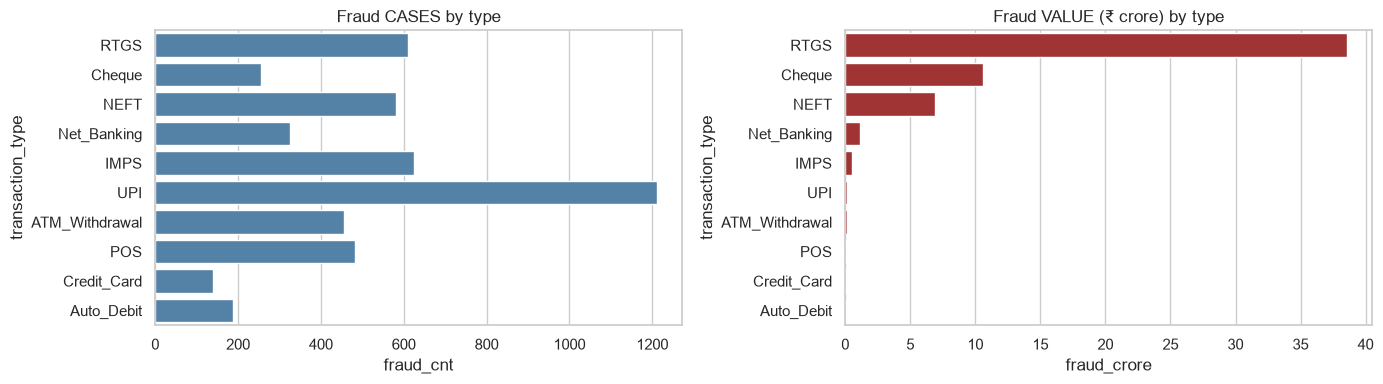

In [5]:
t = (df.groupby("transaction_type")
       .agg(txns=("is_fraud", "size"),
            fraud_cnt=("is_fraud", "sum"),
            fraud_rate_pct=("is_fraud", lambda s: s.mean() * 100),
            fraud_crore=("fraud_amount", lambda s: s.sum() / 1e7))
       .sort_values("fraud_crore", ascending=False)
       .reset_index())
print(t)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=t, x="fraud_cnt", y="transaction_type", color="steelblue", ax=ax[0])
ax[0].set_title("Fraud CASES by type")
sns.barplot(data=t, x="fraud_crore", y="transaction_type", color="firebrick", ax=ax[1])
ax[1].set_title("Fraud VALUE (₹ crore) by type")
plt.tight_layout()
plt.show()

         transaction_amount    txns  fraud_rate_pct
0           (0.0, 100000.0]  513921            0.80
1      (100000.0, 200000.0]   16334            0.80
2      (200000.0, 300000.0]    7323            0.83
3      (300000.0, 400000.0]    3976            1.18
4      (400000.0, 450000.0]    1333            0.75
5      (450000.0, 500000.0]    1088            1.10
6      (500000.0, 550000.0]     852            7.63
7      (550000.0, 600000.0]     721            8.32
8      (600000.0, 700000.0]    1016            9.35
9      (700000.0, 800000.0]     753            8.63
10    (800000.0, 1000000.0]     937            7.04
11   (1000000.0, 2000000.0]    1362            7.93
12  (2000000.0, 10000000.0]     384            9.38


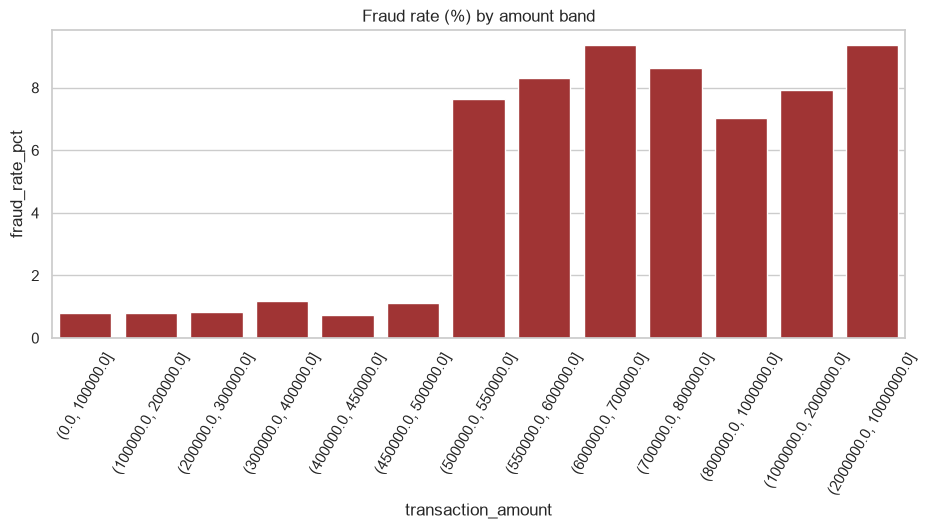

In [6]:
edges = [0, 1e5, 2e5, 3e5, 4e5, 4.5e5, 5e5, 5.5e5, 6e5, 7e5, 8e5, 1e6, 2e6, 1e7]
bands = pd.cut(df["transaction_amount"], edges)

scan = (df.groupby(bands, observed=True)
          .agg(txns=("is_fraud", "size"),
               fraud_rate_pct=("is_fraud", lambda s: s.mean() * 100))
          .reset_index())
scan["transaction_amount"] = scan["transaction_amount"].astype(str)
print(scan)

plt.figure(figsize=(11, 4))
sns.barplot(data=scan, x="transaction_amount", y="fraud_rate_pct", color="firebrick")
plt.xticks(rotation=60)
plt.title("Fraud rate (%) by amount band")
plt.show()

In [7]:
for th in [450_000, 499_999, 500_000, 550_000]:
    sub = df[df["transaction_amount"] > th]
    print(f"> ₹{th:>9,}: {len(sub):>5,} txns, fraud rate {sub['is_fraud'].mean()*100:.2f}%")

# Very close to the line: just below vs just above
near = df[(df["transaction_amount"] > 480_000) & (df["transaction_amount"] <= 520_000)]
near = near.assign(side=np.where(near["transaction_amount"] > 500_000, "above 5L", "below 5L"))
print(near.groupby("side")["is_fraud"].agg(["size", lambda s: s.mean() * 100]))

> ₹  450,000: 7,113 txns, fraud rate 7.13%
> ₹  499,999: 6,025 txns, fraud rate 8.22%
> ₹  500,000: 6,025 txns, fraud rate 8.22%
> ₹  550,000: 5,173 txns, fraud rate 8.31%
          size  <lambda_0>
side                      
above 5L   339        9.14
below 5L   409        1.47


In [8]:
df["is_high_value"] = (df["transaction_amount"] > 500_000).astype(int)

cmp = (df.groupby("is_high_value")
         .agg(txns=("is_fraud", "size"),
              fraud_rate_pct=("is_fraud", lambda s: s.mean() * 100),
              fraud_crore=("fraud_amount", lambda s: s.sum() / 1e7)))
print(cmp)

                 txns  fraud_rate_pct  fraud_crore
is_high_value                                     
0              543975            0.80         9.19
1                6025            8.22        49.01


Review top  0.5% -> 54.0% of fraud VALUE, 4.4% of fraud CASES
Review top    1% -> 80.6% of fraud VALUE, 9.3% of fraud CASES
Review top  1.1% -> 84.3% of fraud VALUE, 10.2% of fraud CASES
Review top    2% -> 87.9% of fraud VALUE, 11.3% of fraud CASES
Review top    5% -> 93.1% of fraud VALUE, 14.1% of fraud CASES
Review top   10% -> 96.4% of fraud VALUE, 18.6% of fraud CASES


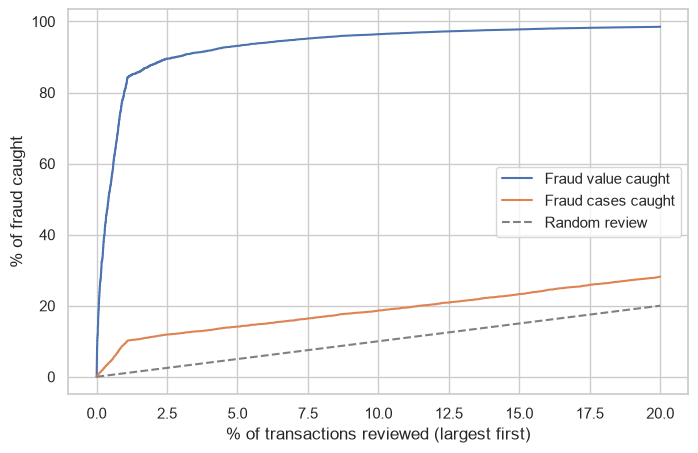

In [9]:
r = df.sort_values("transaction_amount", ascending=False).reset_index(drop=True)
r["pct_reviewed"] = (r.index + 1) / len(r) * 100
r["value_caught_pct"] = r["fraud_amount"].cumsum() / r["fraud_amount"].sum() * 100
r["cases_caught_pct"] = r["is_fraud"].cumsum() / r["is_fraud"].sum() * 100

for p in [0.5, 1, 1.1, 2, 5, 10]:
    row = r[r["pct_reviewed"] >= p].iloc[0]
    print(f"Review top {p:>4}% -> {row['value_caught_pct']:.1f}% of fraud VALUE, "
          f"{row['cases_caught_pct']:.1f}% of fraud CASES")

sub = r[r["pct_reviewed"] <= 20]
plt.figure(figsize=(8, 5))
sns.lineplot(data=sub, x="pct_reviewed", y="value_caught_pct", label="Fraud value caught")
sns.lineplot(data=sub, x="pct_reviewed", y="cases_caught_pct", label="Fraud cases caught")
plt.plot([0, 20], [0, 20], "--", color="gray", label="Random review")
plt.xlabel("% of transactions reviewed (largest first)")
plt.ylabel("% of fraud caught")
plt.legend()
plt.show()

transaction_status
Failed        69.69
Pending       33.45
Reversed      32.58
Success    1,509.18
Name: amount_crore, dtype: float64
Not-success total (₹ cr): 135.7
  transaction_type  fail_rate_pct  stuck_crore
0             RTGS           8.04        71.67
1           Cheque           7.94        25.73
2             NEFT           7.91        22.41
3      Net_Banking           7.93         6.55
4             IMPS           8.01         4.35
5              UPI           7.89         1.67
6   ATM_Withdrawal           7.91         1.06
7              POS           8.07         0.96
8      Credit_Card           7.88         0.68
9       Auto_Debit           8.08         0.62


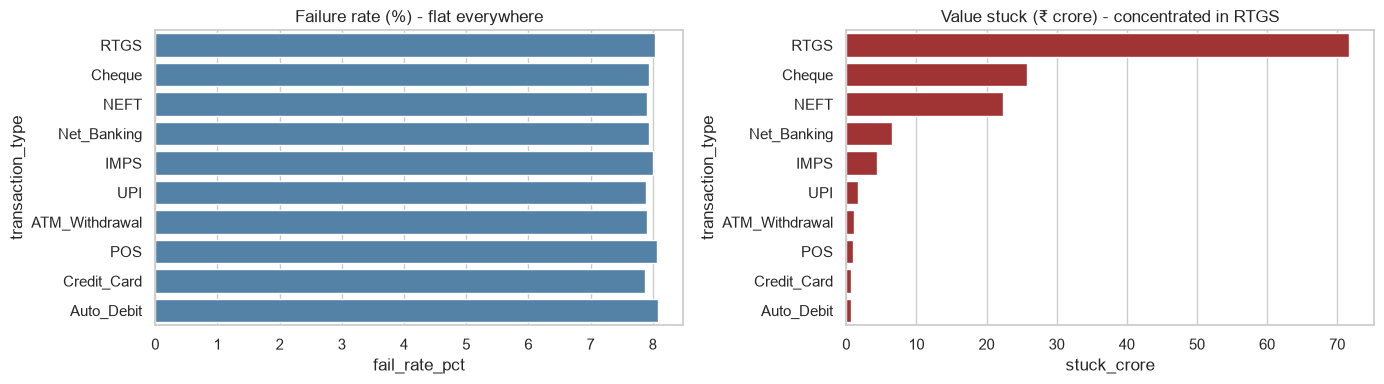

channel
API            8.12
ATM            7.91
Branch         8.00
Mobile_App     7.94
POS_Terminal   8.00
Web            7.91
Name: is_not_success, dtype: float64


In [10]:
# Value by status
status_val = df.groupby("transaction_status")["amount_crore"].sum()
print(status_val)
print("Not-success total (₹ cr):", round(df.loc[df.is_not_success == 1, "amount_crore"].sum(), 1))

# Failure rate vs value at stake, by type
p2 = (df.groupby("transaction_type")
        .apply(lambda g: pd.Series({
            "fail_rate_pct": g["is_not_success"].mean() * 100,
            "stuck_crore": g.loc[g.is_not_success == 1, "amount_crore"].sum()}),
            include_groups=False)
        .sort_values("stuck_crore", ascending=False)
        .reset_index())
print(p2)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=p2, x="fail_rate_pct", y="transaction_type", color="steelblue", ax=ax[0])
ax[0].set_title("Failure rate (%) - flat everywhere")
sns.barplot(data=p2, x="stuck_crore", y="transaction_type", color="firebrick", ax=ax[1])
ax[1].set_title("Value stuck (₹ crore) - concentrated in RTGS")
plt.tight_layout()
plt.show()

# Is failure explained by channel?
print((df.groupby("channel")["is_not_success"].mean() * 100).round(2))

kyc_status
Expired       67.70
Pending      135.45
Verified   1,441.74
Name: amount_crore, dtype: float64
Not-verified value (₹ cr): 203.1
₹10L+ with KYC not verified: 218 txns, ₹ 38.5 cr


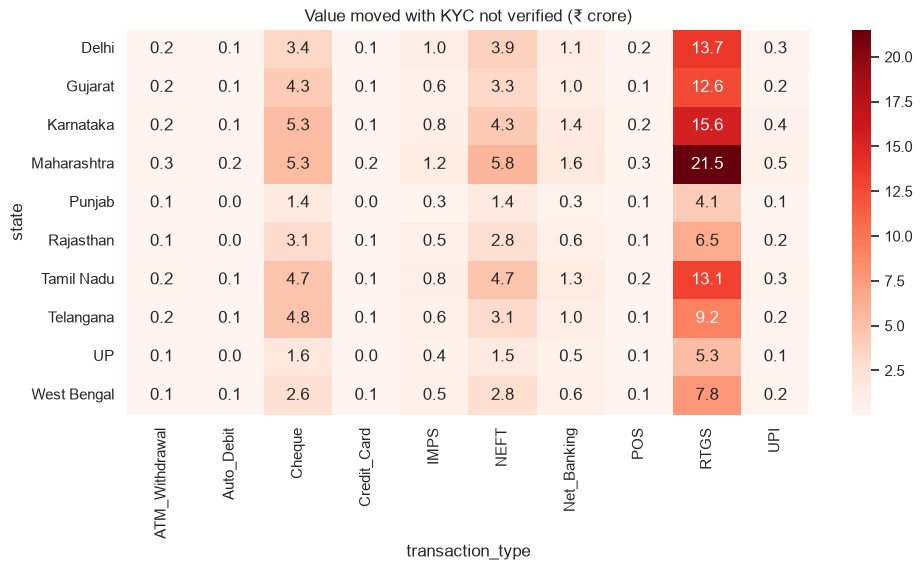

In [11]:
print(df.groupby("kyc_status")["amount_crore"].sum())

nv = df[df["kyc_not_verified"] == 1]
print("Not-verified value (₹ cr):", round(nv["amount_crore"].sum(), 1))

# High-value transactions (₹10L+) done while KYC was Pending/Expired
hv = nv[nv["transaction_amount"] >= 1_000_000]
print("₹10L+ with KYC not verified:", len(hv), "txns, ₹", round(hv["amount_crore"].sum(), 1), "cr")

# Where is the exposure? State x type heatmap
pivot = nv.pivot_table(index="state", columns="transaction_type",
                       values="amount_crore", aggfunc="sum")
plt.figure(figsize=(11, 5))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds")
plt.title("Value moved with KYC not verified (₹ crore)")
plt.show()

In [12]:
out = df.copy()
out["amount_band"] = out["amount_band"].astype(str)
out["transaction_date"] = out["transaction_date"].dt.strftime("%Y-%m-%d")
out["txn_datetime"] = out["txn_datetime"].dt.strftime("%Y-%m-%d %H:%M:%S")

out.to_csv("transactions_clean.csv", index=False)
print(out.shape)

(550000, 30)
